# Explore ODE evaluation caches locally

This notebook reads the per-test-example evaluation results for both seeds, all 52 main models per seed, and the 9 architecture variants per seed. It does not load models or rerun inference. The archive contains each trajectory's all-token coordinate MSE, mean output prediction, true target, parameter, and query time, along with metrics and training metadata.

Plots use equal-weight averages across the two trained seeds (errors, not predictions). Test-error bands are within-seed bootstrap intervals for this average, conditional on the trained models, not across-training-seed confidence intervals. Original figure filenames are retained.


In [1]:
from pathlib import Path
import sys

REPO = Path.cwd().resolve()
while not (REPO / "src" / "ode_paper").is_dir() and REPO != REPO.parent:
    REPO = REPO.parent
if not (REPO / "src" / "ode_paper").is_dir():
    raise RuntimeError("Run this notebook from inside the Paper repo.")
sys.path.insert(0, str(REPO / "src"))
DOWNLOADS = REPO / "evaluation_cache_downloads"
DOWNLOADS.mkdir(parents=True, exist_ok=True)
print("Repo:", REPO)
print("Place the two downloaded tar.gz files here:", DOWNLOADS)

Repo: <repo>
Place the two downloaded tar.gz files here: <repo>/evaluation_cache_downloads


## Download the complete cache bundles

First upload `hpc/export_evaluations.py` to the HPC repository, run it there to create one archive per seed, then download both archives into `evaluation_cache_downloads/`. The exact commands are in the handoff instructions. Each bundle contains 549 evaluations (61 models × 9 inference sizes), with checksums. It excludes checkpoints and generated training banks.

In [2]:
import tarfile

archives = [DOWNLOADS / f"evaluation_seed_{seed}.tar.gz" for seed in (20260906, 20260907)]
missing = [p for p in archives if not p.is_file()]
if missing:
    print("Still need to download:")
    for path in missing:
        print(" ", path)
else:
    for archive in archives:
        with tarfile.open(archive, "r:gz") as bundle:
            bundle.extractall(DOWNLOADS, filter="data")
        print("Extracted", archive.name)

Extracted evaluation_seed_20260906.tar.gz
Extracted evaluation_seed_20260907.tar.gz


## Load and verify

The loader checks archive file checksums, cache identities, and seed labels. It then computes both per-trajectory losses from the saved arrays. The 95% intervals are pointwise, percentile-bootstrap intervals (5,000 resamples of all 8,192 test trajectories) across test trajectories, conditional on each trained model.

In [3]:
from ode_paper.local_results import load_results, select, example_arrays, example_losses

rows = load_results(DOWNLOADS, verify=True)
assert len(rows) == 2 * 61 * 9, f"Expected 1098 model/context evaluations, got {len(rows)}"
for seed in (20260906, 20260907):
    seed_rows = [r for r in rows if r["seed"] == seed]
    print(f"Seed {seed}: {len(seed_rows)} evaluations; "
          f"main={sum(r['group']=='main_experiment' for r in seed_rows)}, "
          f"architecture={sum(r['group']=='architecture_screen' for r in seed_rows)}")
print("Metrics:", ", ".join(k for k in rows[0] if k.endswith("_mse")))

Seed 20260906: 549 evaluations; main=468, architecture=81
Seed 20260907: 549 evaluations; main=468, architecture=81
Metrics: all_token_mse, coordinate_all_token_mse, mean_output_mse, physical_all_token_mse, physical_mean_output_mse


## Inspect individual test examples

`all_token_coordinate_mse` has shape `(test examples, target coordinates)`: it is already averaged over output tokens, with coordinates still separate. `mean_prediction` and `targets` let you recompute error after averaging output tokens. Individual token predictions were not stored.

In [4]:
# Choose any row by filters. Example: first seed's original forced-linear baseline at n=128.
example = next(r for r in rows if r["group"] == "main_experiment" and
               r["family"] == "forced_linear" and r["task"] == "parameter" and
               r["M"] == 2**19 and r["train_n"] == 128 and
               r["inference_n"] == 128 and r["seed"] == 20260906)
arrays = example_arrays(example)
print("variant:", example["variant"], "seed:", example["seed"],
      "n_inference:", example["inference_n"], "examples:", len(arrays["targets"]))
print("Stored arrays:", {key: value.shape for key, value in arrays.items()})
print("First 10 all-token per-example errors:", example_losses(example)[:10])
print("First 10 mean-output per-example errors:", example_losses(example, "mean_output_mse")[:10])

variant: baseline seed: 20260906 n_inference: 128 examples: 8192
Stored arrays: {'all_token_coordinate_mse': (8192, 3), 'mean_prediction': (8192, 3), 'targets': (8192, 3), 'theta': (8192, 3), 'tau': (8192,)}
First 10 all-token per-example errors: [0.00037016 0.00012377 0.00110171 0.00044098 0.00082747 0.00046036
 0.00028646 0.00122939 0.00025151 0.00014395]
First 10 mean-output per-example errors: [0.0003692  0.00012319 0.0011002  0.00043996 0.00082607 0.0004595
 0.00028566 0.00122825 0.00025038 0.00014334]


## Architecture comparison settings

All models use the forced-linear parameter-estimation task, M=2^19 and training n=128. Colors distinguish architectures. Each curve averages the test errors of seeds 20260906 and 20260907. Shading shows pointwise 95% confidence intervals for mean test error. The dotted vertical line marks training n=128.

Depth, width, heads and activation plots report all-token MSE. The readout comparison reports **mean-output MSE for both models**, including the model trained with all-token loss. Edit the settings and plotting function below to adjust appearance.


In [5]:
import numpy as np
import matplotlib.pyplot as plt
import importlib
import ode_paper.paper_style as _paper_style
importlib.reload(_paper_style)
from ode_paper.paper_style import apply_style, PAIR_SIZE, SINGLE_SIZE, PANEL_SIZE, context_ticks
apply_style()
from ode_paper.seed_average import seed_average

BAND_ALPHA = 0.25
LINE_WIDTH = 2.1
MARKER_SIZE = 4
FIGSIZE = (PANEL_SIZE[0], 3.0)
PAIR_SIZE = (PAIR_SIZE[0], 3.0)
SAVE_PLOTS = True
SHOW_BANDS = True
SEEDS_TO_PLOT = (20260906, 20260907)
SEED_STYLES = {20260906: "-", 20260907: "--"}
COLORS = plt.rcParams["axes.prop_cycle"].by_key()["color"]
OUTPUT = REPO / "figures" / "architecture_screen" / "notebook_plots"


# One curve per configuration: arithmetic mean of the two seed-specific risks.
# Bands condition on these trained models; they do not measure training variability.
_AVERAGE_INTERVALS = {}

def averaged_point(error_map, key):
    cache_key = (key, bool(SHOW_BANDS))
    if cache_key not in _AVERAGE_INTERVALS:
        _AVERAGE_INTERVALS[cache_key] = seed_average(error_map, bands=SHOW_BANDS)
    return _AVERAGE_INTERVALS[cache_key]

def row_curve(selected, expected, xkey, metric):
    values = []
    for x in expected:
        errors, keys = {}, []
        for seed in (20260906, 20260907):
            matches = [r for r in selected if r['seed']==seed and r[xkey]==x]
            if len(matches)!=1:
                raise ValueError(f'Missing/duplicate point: {seed}, {xkey}={x}')
            r = matches[0]
            errors[seed] = r['_identifiable_errors'] if metric=='identifiable_combination_mse' else example_losses(r, metric)
            keys.append(str(r['cache']))
        values.append(averaged_point(errors, (tuple(keys), metric)))
    return np.asarray(values).T

def draw_curve(ax, x, values, color, label, marker='o', linestyle='-'):
    mean, low, high = values
    ax.loglog(x, mean, color=color, linestyle=linestyle, marker=marker,
              linewidth=LINE_WIDTH, markersize=MARKER_SIZE, label=label, zorder=3)
    if SHOW_BANDS:
        ax.fill_between(x, np.where(low>0,low,np.nan), high,
                        color=color, alpha=BAND_ALPHA, linewidth=0, zorder=1)

def finish_axis(ax, x, title, xlabel='Inference observations n',
                ylabel='All-token test loss', training_ns=()):
    for n in training_ns:
        ax.axvline(n,color='gray',linestyle=':',linewidth=1,alpha=.65)
    context_ticks(ax, x)
    ax.set(title=title,xlabel=xlabel,ylabel=ylabel)
    ax.grid(True,which='both',alpha=.18)
    ax.legend(loc='upper right',fontsize=10,handlelength=3,framealpha=.95)

def save_pair(fig, folder, filename, keep_ylabels=False, legend_kwargs=None):
    # Paired panels share the same curves, so use one legend below both axes.
    if len(fig.axes) > 1:
        if not keep_ylabels: fig.axes[1].set_ylabel('')
        handles, labels = fig.axes[0].get_legend_handles_labels()
        for ax in fig.axes:
            if ax.get_legend() is not None:
                ax.get_legend().remove()
        kw = dict(fontsize=10, handlelength=3); kw.update(legend_kwargs or {})
        fig.legend(handles, labels, loc='lower center', bbox_to_anchor=(.5, .08),
                   ncol=min(len(labels), 5), framealpha=.95, **kw)
        fig.tight_layout(rect=(0, .16, 1, 1))
    else:
        fig.tight_layout()
    if SAVE_PLOTS:
        folder.mkdir(parents=True,exist_ok=True)
        for ext in ('pdf','png'):
            fig.savefig(folder/f'{filename}.{ext}',dpi=180)

architecture_rows = [r for r in rows if r['group']=='architecture_screen' or
    (r['group']=='main_experiment' and r['family']=='forced_linear'
     and r['task']=='parameter' and r['train_n']==128 and r['M']==2**19)]

def plot_architecture(variants, labels, *, title, filename, metric='all_token_mse', figsize=None):
    ns=(2,4,8,16,32,64,128,256,512)
    fig,ax=plt.subplots(figsize=figsize or (FIGSIZE[0], 2.6))
    for i,variant in enumerate(variants):
        selected=[r for r in architecture_rows if r['variant']==variant]
        draw_curve(ax,ns,row_curve(selected,ns,'inference_n',metric),COLORS[i],labels[variant])
    finish_axis(ax,ns,'Parameter estimation (FL)',ylabel=('Mean-output test loss' if metric=='mean_output_mse'
                                 else 'All-token test loss'),training_ns=(128,))
    save_pair(fig,OUTPUT,filename)
    return fig,ax


## Depth comparison

All-token MSE; 8, 16 and 32 blocks. Hidden width 64, FFN width 256, two heads.


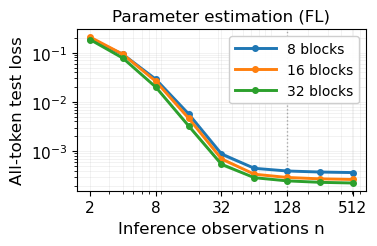

In [6]:
fig, ax = plot_architecture(
    ("depth_8", "baseline", "depth_32"),
    {"depth_8": "8 blocks", "baseline": "16 blocks", "depth_32": "32 blocks"},
    title="Depth comparison",
    filename="depth_inference_scaling",
    metric="all_token_mse",
)
plt.show()


## Width comparison

All-token MSE; hidden/FFN widths 32/128, 64/256 and 128/512. Depth 16, two heads.


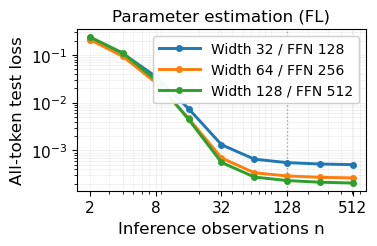

In [7]:
fig, ax = plot_architecture(
    ("width_32", "baseline", "width_128"),
    {"width_32": "Width 32 / FFN 128", "baseline": "Width 64 / FFN 256", "width_128": "Width 128 / FFN 512"},
    title="Width comparison",
    filename="width_inference_scaling",
    metric="all_token_mse",
)
plt.show()


## Head comparison

All-token MSE; 1, 2, 4 and 8 full-width global heads. Depth 16, hidden width 64.


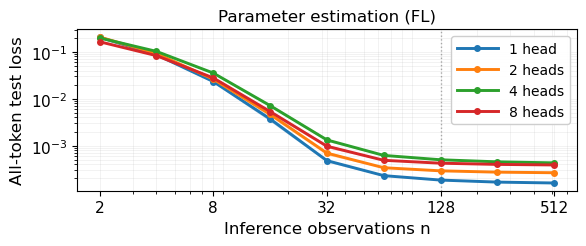

In [8]:
fig, ax = plot_architecture(
    ("heads_1", "baseline", "heads_4", "heads_8"),
    {"heads_1": "1 head", "baseline": "2 heads", "heads_4": "4 heads", "heads_8": "8 heads"},
    title="Attention-head comparison",
    filename="heads_inference_scaling",
    metric="all_token_mse",
    figsize=(6.0, 2.6),
)
plt.show()


## Activation comparison

All-token MSE; squared ReLU versus ReLU. Depth 16, hidden width 64, two heads.


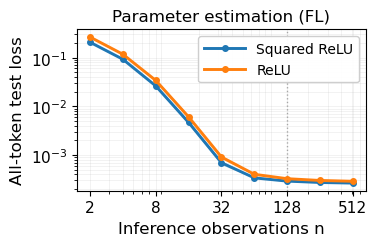

In [9]:
fig, ax = plot_architecture(
    ("baseline", "relu"),
    {"baseline": "Squared ReLU", "relu": "ReLU"},
    title="Activation comparison",
    filename="activation_inference_scaling",
    metric="all_token_mse",
)
plt.show()


## Readout / training-loss comparison

Both curves use **mean-output test MSE**: average the output tokens first, then square the error and average over parameter coordinates. Compare the model trained with all-token loss against the model trained with mean-output loss.


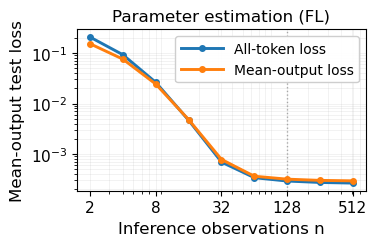

In [10]:
fig, ax = plot_architecture(
    ("baseline", "mean_output"),
    {"baseline": "All-token loss", "mean_output": "Mean-output loss"},
    title="Readout-loss comparison",
    filename="readout_inference_scaling",
    metric="mean_output_mse",
)
plt.show()


## Forced linear: matched training and inference context, both tasks

Parameter estimation is on the left; trajectory prediction is on the right. Each point uses a model trained and evaluated at the same n, with one color per M and one curve averaging the two seed-specific errors.


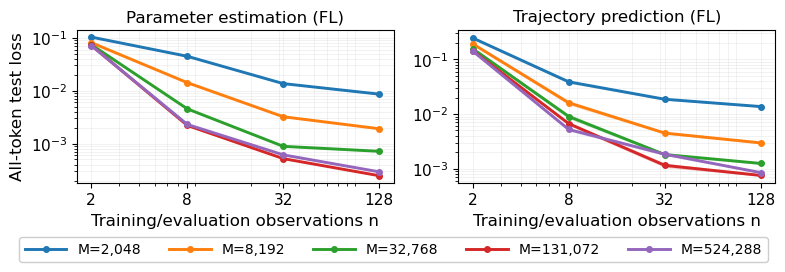

In [11]:
MATCHED_METRIC = "all_token_mse"
MATCHED_NS = (2, 8, 32, 128)
MATCHED_SIZES = (2**11, 2**13, 2**15, 2**17, 2**19)
INFERENCE_NS = (2, 4, 8, 16, 32, 64, 128, 256, 512)

def plot_forced_linear_pair(mode):
    if mode=='matched_n':
        groups, xs, xkey = MATCHED_SIZES, MATCHED_NS, 'train_n'
        xlabel,heading='Training/evaluation observations n','Forced linear: training n = inference n'
    elif mode=='matched_M':
        groups, xs, xkey = MATCHED_NS, MATCHED_SIZES, 'M'
        xlabel,heading='Number of training trajectories M','Forced linear: training n = inference n'
    elif mode=='inference_n':
        groups, xs, xkey = MATCHED_SIZES, INFERENCE_NS, 'inference_n'
        xlabel,heading='Inference observations n','Forced linear: training n=128'
    else: raise ValueError(mode)
    fig,axes=plt.subplots(1,2,figsize=PAIR_SIZE)
    for ax,task,title in zip(axes,('parameter','prediction'),('Parameter estimation (FL)','Trajectory prediction (FL)')):
        for i,group in enumerate(groups):
            selected=[r for r in rows if r['group']=='main_experiment' and r['family']=='forced_linear' and r['task']==task]
            if mode=='matched_n': selected=[r for r in selected if r['M']==group and r['train_n']==r['inference_n']]
            elif mode=='matched_M': selected=[r for r in selected if r['train_n']==r['inference_n']==group and r['M'] in MATCHED_SIZES]
            else: selected=[r for r in selected if r['M']==group and r['train_n']==128]
            label=f'n={group}' if mode=='matched_M' else f'M={group:,}'
            draw_curve(ax,xs,row_curve(selected,xs,xkey,MATCHED_METRIC),COLORS[i],label)
        finish_axis(ax,xs,title,xlabel=xlabel,training_ns=(128,) if mode=='inference_n' else ())
        if mode=='matched_M': ax.set_xticklabels([f'$2^{{{int(np.log2(m))}}}$' for m in xs])
    save_pair(fig,REPO/'figures/main_experiment/notebook_plots',f'forced_linear_both_tasks_{mode}')
    return fig,axes

fig,axes=plot_forced_linear_pair('matched_n')
plt.show()


## Forced linear: M scaling, both tasks

The x-axis is M. Each color is a training n, evaluated at that same n. The configurations match across the two task panels.


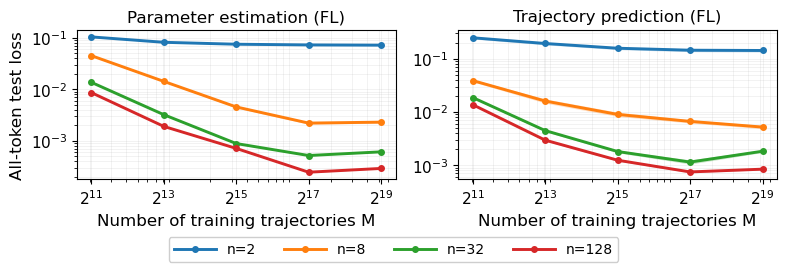

In [12]:
fig, axes = plot_forced_linear_pair("matched_M")
plt.show()


## Forced linear: inference scaling at training n=128, both tasks

The x-axis is inference n, with a color for each M and a dotted line marking training n=128.


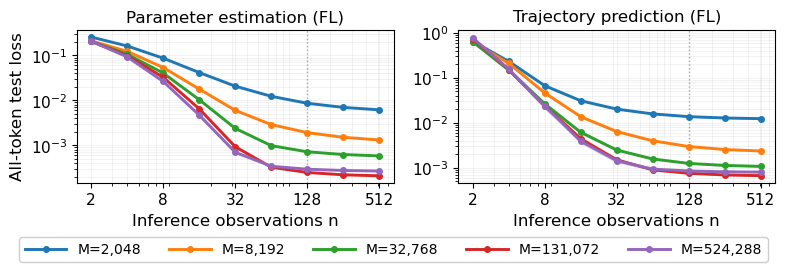

In [13]:
fig, axes = plot_forced_linear_pair("inference_n")
plt.show()


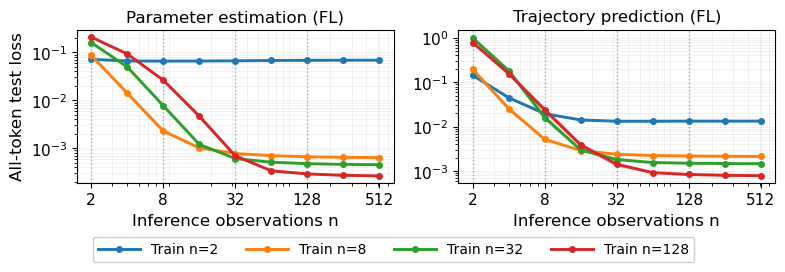

In [14]:
def plot_family_inference(family, family_title, parameter_metric='all_token_mse', training_ns=(8,128)):
    ns=(2,4,8,16,32,64,128,256,512)
    ab={'forced_linear':'FL','logistic':'LG','birth_death':'BD','stuart_landau':'SL'}[family]
    fig,axes=plt.subplots(1,2,figsize=PAIR_SIZE)
    for ax,task,title in zip(axes,('parameter','prediction'),(f'Parameter estimation ({ab})',f'Trajectory prediction ({ab})')):
        metric=parameter_metric if task=='parameter' else 'all_token_mse'
        for i,train_n in enumerate(training_ns):
            selected=[r for r in rows if r['group']=='main_experiment' and r['family']==family
                      and r['task']==task and r['M']==2**19 and r['train_n']==train_n]
            draw_curve(ax,ns,row_curve(selected,ns,'inference_n',metric),COLORS[i],f'Train n={train_n}')
        ylabel=('MSE of (b-d,c)' if metric=='identifiable_combination_mse'
                else 'All-token test loss')
        finish_axis(ax,ns,title,ylabel=ylabel,training_ns=training_ns)
    save_pair(fig,REPO/'figures/main_experiment/notebook_plots',f'{family}_both_tasks_M524288_inference_by_training_n')
    return fig,axes

fig,axes=plot_family_inference('forced_linear','Forced linear',training_ns=(2,8,32,128))
plt.show()


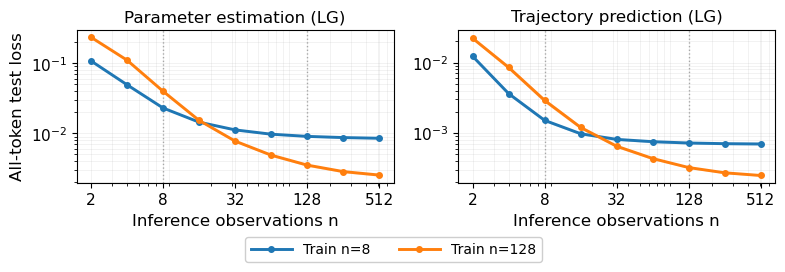

In [15]:
fig,axes=plot_family_inference('logistic','Logistic growth')
plt.show()


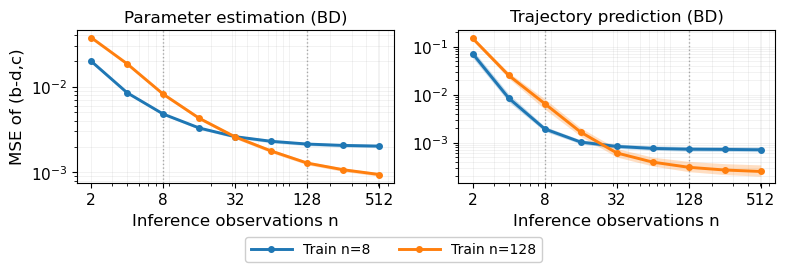

In [16]:
from ode_paper.families import decode

for r in rows:
    if (
        r["group"] == "main_experiment"
        and r["family"] == "birth_death"
        and r["task"] == "parameter"
    ):
        arrays = example_arrays(r)

        # Decode the mean prediction into physical parameter units.
        estimated = decode(
            arrays["mean_prediction"].astype(float), "birth_death"
        )
        truth = arrays["theta"].astype(float)

        # Identifiable vector: (birth - death, competition).
        estimated_combinations = np.column_stack((
            estimated[:, 0] - estimated[:, 1],
            estimated[:, 2],
        ))
        true_combinations = np.column_stack((
            truth[:, 0] - truth[:, 1],
            truth[:, 2],
        ))

        # One scalar loss per test trajectory, averaged over the two coordinates.
        errors = (
            (estimated_combinations - true_combinations)**2
        ).mean(axis=1)

        r["identifiable_combination_mse"] = errors.mean()
        r["_identifiable_errors"] = errors

fig, axes = plot_family_inference(
    "birth_death",
    "Birth–death",
    parameter_metric="identifiable_combination_mse",
)
plt.show()

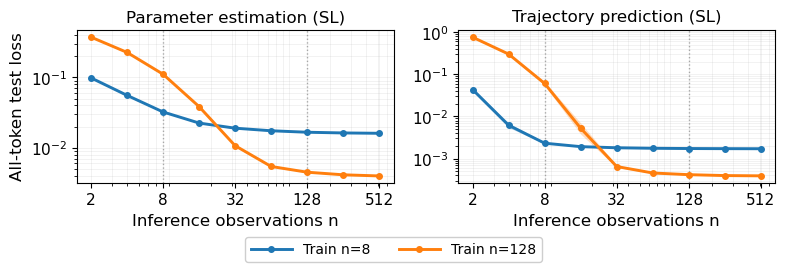

In [17]:
fig, axes = plot_family_inference("stuart_landau", "Stuart–Landau")
plt.show()

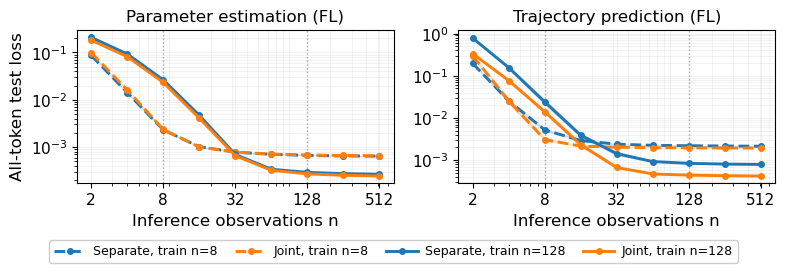

In [18]:
# Joint and separate models: average per-seed risks, never predictions.
import json, hashlib
from ode_paper.families import SPECS, decode
import importlib
from ode_paper import seed_average as _seed_average_module
seed_average = importlib.reload(_seed_average_module).seed_average
STUART_JOINT_128_SEEDS = (20260906, 20260907)

JOINT_OUTPUT = REPO / "figures" / "joint_experiment" / "notebook_plots"
_joint_catalogs = {}
for seed in SEEDS_TO_PLOT:
    base = DOWNLOADS / f"seed_{seed}"
    for group, name in (("joint_experiment", "joint_catalog.json"), ("main_experiment", "catalog.json")):
        catalog = json.loads((base/name).read_text())
        assert catalog["seed"] == seed and catalog["format_version"] == 1
        _joint_catalogs[seed, group] = (base, catalog)

def _comparison_arrays(family, task, train_n, seed, inference_n, joint):
    group = "joint_experiment" if joint else "main_experiment"
    base, catalog = _joint_catalogs[seed, group]
    entries = [e for e in catalog["evaluations"] if e["group"] == group
               and e["config"]["family"] == family and e["config"]["task"] == ("joint" if joint else task)
               and e["config"]["M"] == 2**19 and e["config"]["n"] == train_n
               and e["inference_n"] == inference_n]
    if len(entries) != 1: raise ValueError(f"Missing/duplicate evaluation: {family,task,train_n,seed,inference_n,joint}")
    entry = entries[0]; cache = base/entry["cache"]
    for path in (cache/"metrics.json", cache/"per_example.npz"):
        assert path.resolve().is_relative_to(base.resolve())
        assert hashlib.sha256(path.read_bytes()).hexdigest() == catalog["sha256"][path.relative_to(base).as_posix()]
    record = json.loads((cache/"metrics.json").read_text())
    assert record["identity"]["config"] == entry["config"] and record["identity"]["n"] == inference_n
    with np.load(cache/"per_example.npz", allow_pickle=False) as z:
        a = {k:z[k].copy() for k in ("all_token_coordinate_mse", "targets", "theta", "tau", "mean_prediction")}
    p = len(SPECS[family]["low"])
    sl = (slice(0,p) if task == "parameter" else slice(p,None)) if joint else slice(None)
    errors = a["all_token_coordinate_mse"][:,sl].astype(float).mean(axis=1)
    key = (("parameter" if task == "parameter" else "trajectory") + "_all_token_mse") if joint else "all_token_mse"
    assert len(errors) == 8192 and np.isfinite(errors).all() and (errors >= 0).all()
    assert np.isclose(errors.mean(), record["metrics"][key], rtol=1e-6)
    if family == 'birth_death' and task == 'parameter':
        # Cached mean outputs permit combination error; tokenwise cross-errors are not saved.
        estimate = decode(a['mean_prediction'][:,sl].astype(float), family)
        true = a['theta']
        delta = np.stack(((estimate[:,0]-estimate[:,1])-(true[:,0]-true[:,1]),
                          estimate[:,2]-true[:,2]), axis=1)
        errors = (delta**2).mean(axis=1)
        assert np.isfinite(errors).all()
        key = 'identifiable_combination_mean_output_physical_mse_v1'
    return errors, a["targets"][:,sl], a["theta"], a["tau"], (str(cache),key)

def plot_joint_comparison(family,title):
    ns=(2,4,8,16,32,64,128,256,512)
    # Only this joint configuration has five runs; other curves retain two.
    if family == 'stuart_landau':
        for seed in STUART_JOINT_128_SEEDS:
            base = DOWNLOADS / f'seed_{seed}'
            catalog = json.loads((base/'joint_catalog.json').read_text())
            assert catalog['seed'] == seed and catalog['format_version'] == 1
            _joint_catalogs[seed, 'joint_experiment'] = (base, catalog)
    ab={'forced_linear':'FL','logistic':'LG','birth_death':'BD','stuart_landau':'SL'}[family]
    fig,axes=plt.subplots(1,2,figsize=PAIR_SIZE)
    for ax,task,heading in zip(axes,('parameter','prediction'),(f'Parameter estimation ({ab})',f'Trajectory prediction ({ab})')):
        for ni,train_n in enumerate((8,128)):
            for joint in (False,True):
                seeds = (STUART_JOINT_128_SEEDS if family=='stuart_landau' and joint and train_n==128
                         else (20260906,20260907))
                values=[]
                for n in ns:
                    errors_by_seed,keys={},[]
                    for seed in seeds:
                        errors,targets,theta,tau,key=_comparison_arrays(family,task,train_n,seed,n,joint)
                        if joint and seed in (20260906,20260907):
                            _,ot,op,oq,_=_comparison_arrays(family,task,train_n,seed,n,False)
                            assert np.array_equal(targets,ot) and np.array_equal(theta,op) and np.array_equal(tau,oq), 'Unpaired test banks'
                        errors_by_seed[seed]=errors;keys.append(key)
                    values.append(averaged_point(errors_by_seed,tuple(keys)))
                draw_curve(ax,ns,np.asarray(values).T,COLORS[int(joint)],
                           f"{'Joint' if joint else 'Separate'}, train n={train_n}",
                           linestyle='--' if train_n==8 else '-')
        finish_axis(ax,ns,heading,training_ns=(8,128))
        if family == 'birth_death' and task == 'parameter':
            ax.set_ylabel('MSE of (b-d,c)')
        if family == 'birth_death' and task == 'prediction':
            ax.set_ylabel('All-token test loss')
    save_pair(fig,JOINT_OUTPUT,f'{family}_joint_vs_separate',keep_ylabels=(family=='birth_death'),
              legend_kwargs=dict(fontsize=9, handlelength=2.5, columnspacing=1.4, handletextpad=0.6))
    return fig,axes

fig,axes=plot_joint_comparison('forced_linear','Forced linear')
plt.show()


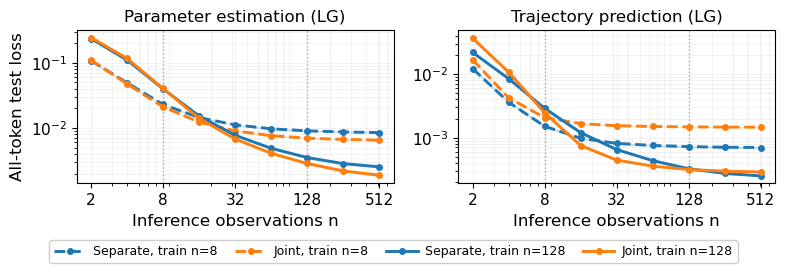

In [19]:
fig, axes = plot_joint_comparison("logistic", "Logistic growth")
plt.show()

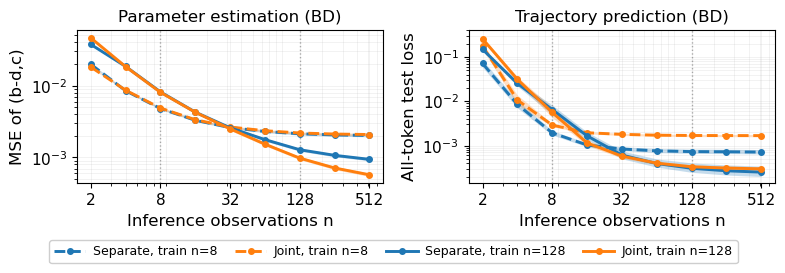

In [20]:
fig, axes = plot_joint_comparison("birth_death", "Birth–death")
plt.show()

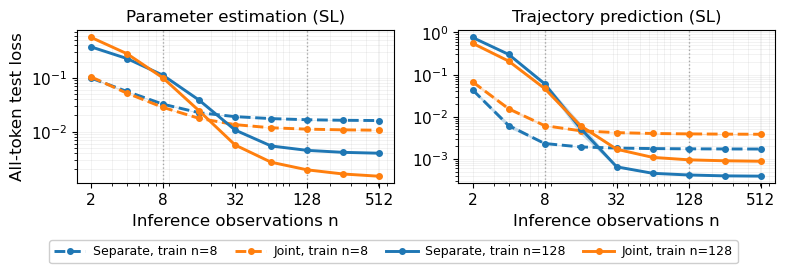

In [21]:
# Joint n=128: five-seed average. Other curves: original two-seed averages.
fig, axes = plot_joint_comparison("stuart_landau", "Stuart–Landau")
plt.show()